# Pandera, checks at the door

Optional, self-paced: goes deeper than Session 3.3.

CPU only. Reads best after `tools/dbt` §9 (dbt tests). A payment provider sends Qafila a day of
payments. You check it with hand-written asserts, watch what they miss, then write the same rules once as a
**Pandera schema**: every problem at once, row by row, and the bad rows set aside while the good ones go on.

**The data:** eight invented payments (SAR) with six problems hidden in them, few enough to check by eye. The last
section runs the same kind of schema on the real payments feed.

🤔 asks you to predict before you run a cell · 🔍 says what the output means · ➕ sections are for your own pace.

**Contents**
- [ ] 1 · The problem: checks written by hand
- [ ] 2 · The mental model: a schema, a validation, a report
- [ ] 3 · A first schema
- [ ] 4 · Types and nulls, before any rule
- [ ] 5 · Built-in checks, and every failure at once
- [ ] 6 · Your own checks: one column, or the whole row
- [ ] 7 · Quarantine: good rows on, bad rows aside
- [ ] 8 · Pandera and dbt tests: where each rule belongs
- [ ] 9 · The real feed ➕
- [ ] 10 · Summary

🎓 **Instructor notes** (instructor copy only)

- D3_3 opens with `tools/dbt` §9 (10'), then this walkthrough. Core ≈ 16': §1 2' · §2 1' · §3 1' · §4 2' · §5 3' ·
  §6 2' · §7 2' · §8 2' · §10 1'. §9 is ➕. §8 links the two halves of the session: the same rules, at the door
  (Pandera) and in the warehouse (dbt).
- §5 to §7 each build what the next one uses (`Payment`, `failures2`, `clean`): run them in order.
- In class, run the cells of a ➕ section without stopping on them: later cells may use what they build.
- Lab 3.3 task 4 asks for the `SupplierPrice` model and task 5 quarantines the bad rows: here the same mechanism runs on
  payments, so don't write the supplier schema in class.
- Expect "why not Great Expectations / Soda?": same job (declared expectations, a report). Pandera is a library that
  lives in the pipeline's Python, next to the DataFrame; the others add their own config, stores and reports.
  Pydantic checks one record at a time (an API payload), not a DataFrame.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "polars>=1.30", "pandera[polars]>=0.22"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import warnings
from datetime import datetime

warnings.filterwarnings("ignore", category=FutureWarning)   # pyspark's pandas-3 notice, via pandera
import polars as pl
import pandera.polars as pa
from pandera.polars import PolarsData
from IPython.display import display
import de_utils as U
import de_viz as V

pl.Config.set_tbl_rows(12)
pl.Config.set_fmt_str_lengths(40)
OUT = U.lab_dir("tools_pandera", reset=True)
print("Output folder:", OUT)

Output folder: /content/data-engineering/labs\artifacts\tools_pandera


Pandera **tests**, like dbt, but earlier: it checks a DataFrame against declared rules, in Python, before a file or
an API batch is loaded into the warehouse.

In [2]:
V.platform_map(tool="pandera")

Monday's export from the payment provider, which Finance reconciles against the orders. A payment is `captured`
(money taken), `refunded` (given back) or `failed`. Six things are wrong in these eight rows: try to spot some before
the checks do.

In [3]:
def ts(text):
    return datetime.fromisoformat(text) if text else None


PAYMENTS = pl.DataFrame({
    "payment_id": [9001, 9002, 9003, 9003, 9005, 9006, 9007, 9008],
    "order_id":   [101, 102, 103, 103, 105, 106, 107, 108],
    "amount":     [275.86, 33.65, 12.00, 12.00, -5.00, 44.00, None, 58.10],
    "method":     ["card", "wallet", "card", "card", "card", "cheque", "wallet", "Card"],
    "status":     ["captured", "refunded", "captured", "captured", "captured", "captured", "captured", "captured"],
    "captured_at": [ts(f"2026-09-14 {h}") for h in
                    ["09:05", "10:10", "11:20", "11:20", "12:00", "12:45", "13:30", "14:15"]],
    "refunded_at": [None, ts("2026-09-14 09:40"), None, None, None, None, None, None],
})
PAYMENTS

payment_id,order_id,amount,method,status,captured_at,refunded_at
i64,i64,f64,str,str,datetime[μs],datetime[μs]
9001,101,275.86,"""card""","""captured""",2026-09-14 09:05:00,null
9002,102,33.65,"""wallet""","""refunded""",2026-09-14 10:10:00,2026-09-14 09:40:00
9003,103,12.0,"""card""","""captured""",2026-09-14 11:20:00,null
9003,103,12.0,"""card""","""captured""",2026-09-14 11:20:00,null
9005,105,-5.0,"""card""","""captured""",2026-09-14 12:00:00,null
9006,106,44.0,"""cheque""","""captured""",2026-09-14 12:45:00,null
9007,107,null,"""wallet""","""captured""",2026-09-14 13:30:00,null
9008,108,58.1,"""Card""","""captured""",2026-09-14 14:15:00,null


## 1 · The problem: checks written by hand

The usual first version: a function with a few asserts, run before the load.

In [4]:
def check_by_hand(df):
    assert df["payment_id"].is_unique().all(), "payment_id is not unique"
    assert (df["amount"] > 0).all(), "amount must be positive"
    assert df["method"].is_in(["card", "wallet", "cash"]).all(), "unknown payment method"
    print("✅ all checks passed")


try:
    check_by_hand(PAYMENTS)
except AssertionError as e:
    print("❌", e)

❌ payment_id is not unique


🔍 It stops at the first problem, without saying which payment, or how many other problems there are.

🤔 **Predict** · Someone removes the duplicate and the negative amount. What does the check say about the six rows
that are left?

In [5]:
fixed = PAYMENTS.unique("payment_id", keep="first", maintain_order=True).filter(pl.col("amount") != -5.00)
try:
    check_by_hand(fixed)
except AssertionError as e:
    print("❌", e)
print("is (null > 0) true for every row?", (pl.Series([12.0, None]) > 0).all())

❌ unknown payment method
is (null > 0) true for every row? True


🔍 It complains about the method, fine. But payment 9007 has **no amount**, and the amount check passed it:
`(amount > 0).all()` skips nulls. And the refund recorded **before** its capture (9002)? No check even looks.

## 2 · The mental model: a schema, a validation, a report

```
  schema (a class)                      validate(df)                    result
  column: type, nullable,     ───►  1. columns there? types right?  ───►  the same DataFrame      (all good)
          checks (gt, isin…)        2. each column's checks              SchemaError            (first failure)
  frame:  checks across columns     3. the frame's checks                SchemaErrors + report  (lazy=True: all)
```

Validation doesn't change the data. It either hands it back or raises, with a report of what failed.

## 3 · A first schema

A schema is a class: one attribute per column, its type, and its checks.

In [6]:
class Hello(pa.DataFrameModel):
    payment_id: int
    amount: float = pa.Field(gt=0)


good = PAYMENTS.head(3).select("payment_id", "amount")
Hello.validate(good)

payment_id,amount
i64,f64
9001,275.86
9002,33.65
9003,12.0


🔍 `validate` returns the DataFrame, so it fits in a chain: `Hello.validate(df).write_parquet(...)`.

🤔 **Predict** · And the full export, with its negative and missing amounts?

In [7]:
try:
    Hello.validate(PAYMENTS)
except pa.errors.SchemaError as e:
    print("❌", type(e).__name__, "·", str(e).splitlines()[0])

❌ SchemaError · non-nullable column 'amount' contains null values


🔍 It reports the `null` and stops: one error at a time, like the asserts. §5 asks for all of them.

## 4 · Types and nulls, before any rule

Each column is checked in this order: is it there, is its **type** right, are there **nulls**, then its checks.
Files often arrive as text: here is the export read from a CSV, every column a string.

In [8]:
PAYMENTS.write_csv(OUT / "payments_2026-09-14.csv")
as_text = pl.read_csv(OUT / "payments_2026-09-14.csv", infer_schema=False)
print(as_text.schema)
try:
    Hello.validate(as_text)
except pa.errors.SchemaError as e:
    print("❌", str(e).splitlines()[0])

Schema({'payment_id': String, 'order_id': String, 'amount': String, 'method': String, 'status': String, 'captured_at': String, 'refunded_at': String})
❌ expected column 'payment_id' to have type Int64, got String


🔍 Pandera doesn't guess: a `String` column is not an `int` column. Either parse the file yourself (Lab 3.3 must,
because its supplier writes `9,49`), or ask Pandera to **coerce** each column to the declared type.

In [9]:
class HelloCoerced(pa.DataFrameModel):
    payment_id: int
    amount: float = pa.Field(gt=0, nullable=True)

    class Config:
        coerce = True


HelloCoerced.validate(as_text.head(3)).schema

Schema([('payment_id', Int64),
        ('order_id', String),
        ('amount', Float64),
        ('method', String),
        ('status', String),
        ('captured_at', String),
        ('refunded_at', String)])

🤔 **Predict** · `HelloCoerced` allows nulls in `amount`. Does the full CSV pass now?

In [10]:
try:
    HelloCoerced.validate(as_text)
except pa.errors.SchemaError as e:
    print("❌", str(e).splitlines()[0])

❌ Column 'amount' failed validator number 0: <Check greater_than: greater_than(0)> failure case examples: [{'amount': -5.0}]


🔍 The null is allowed now, so the next problem shows: `-5.0` breaks `gt=0`. Without `nullable=True`, a null fails.
dbt is the other way round: a column may be null until you add a `not_null` test. Pandera's default is the one that
would have caught 9007.

## 5 · Built-in checks, and every failure at once

Finance wants every problem in one report, to send back to the provider. `validate(df, lazy=True)` runs **every**
check and raises `SchemaErrors` (plural) with a table of failures. Here is the full schema, `Payment`:

In [11]:
class Payment(pa.DataFrameModel):
    payment_id: int = pa.Field(unique=True)
    order_id: int
    amount: float = pa.Field(gt=0)
    method: str = pa.Field(isin=["card", "wallet", "cash"])
    status: str = pa.Field(isin=["captured", "refunded", "failed"])


failures = None
try:
    Payment.validate(PAYMENTS, lazy=True)
except pa.errors.SchemaErrors as e:
    failures = e.failure_cases
failures

failure_case,schema_context,column,check,check_number,index
str,str,str,str,i32,i32
"""9003""","""Column""","""payment_id""","""field_uniqueness""",null,2
"""9003""","""Column""","""payment_id""","""field_uniqueness""",null,3
null,"""Column""","""amount""","""not_nullable""",null,6
"""-5.0""","""Column""","""amount""","""greater_than(0)""",0,4
"""cheque""","""Column""","""method""","""isin(['card', 'wallet', 'cash'])""",0,5
"""Card""","""Column""","""method""","""isin(['card', 'wallet', 'cash'])""",0,7


| Check | Fails when |
|---|---|
| `gt`, `ge`, `lt`, `le`, `in_range` | a value is outside the bounds |
| `isin`, `notin` | a value is not in (or is in) a list |
| `str_startswith`, `str_matches`, `str_length` | a string has the wrong shape |
| `unique=True` | a value appears more than once |
| `nullable=True` | (allows nulls; the default rejects them) |

🔍 Six failures: both copies of 9003, the negative, the null, `cheque` and `Card`, each with its row number (`index`,
from 0). A report you can send back to the provider. Still missing: the refund before its capture (9002), because no
check compares two columns yet.

**Break it on purpose.** Pipelines often work on a `LazyFrame` (Polars' plan, not yet run). `lazy=True` above is a
Pandera option; a `LazyFrame` is something else.

🤔 **Predict** · We validate `PAYMENTS.lazy()`. Does the negative amount fail?

In [12]:
checked = Payment.validate(PAYMENTS.lazy())
print(type(checked).__name__, "· no error raised")

LazyFrame · no error raised


🔍 No error. On a `LazyFrame`, Pandera checks only what it can without running the plan: the columns and their
types. The **values** are never looked at. To check them, validate a `DataFrame`: call `.collect()` first.

In [13]:
try:
    Payment.validate(PAYMENTS.lazy().collect())
except pa.errors.SchemaError as e:
    print("❌ collected first, so the values are checked:", str(e).splitlines()[0])

❌ collected first, so the values are checked: column 'payment_id' not unique:


🎓 This one bites in real pipelines: a lazy Polars chain validated "successfully" for months. Ask the room where in
Lab 2.4's lazy chain a check would have to go (answer: after `collect()`, or on the written file).

## 6 · Your own checks: one column, or the whole row

Some rules aren't built in: an amount must be a whole number of halalas. A **column check** receives the column and
returns one `True`/`False` per row.

In [14]:
class PaymentChecked(Payment):                           # every rule of Payment, plus one
    @pa.check("amount", name="at_most_two_decimals")
    def whole_halalas(cls, data: PolarsData) -> pl.LazyFrame:   # data.lazyframe: the rows · data.key: the column
        return data.lazyframe.select(((pl.col(data.key) * 100).round(0) - pl.col(data.key) * 100).abs() < 1e-6)


try:   # a provider bug: 9001's amount arrives as 275.855
    PaymentChecked.validate(PAYMENTS.with_columns(pl.col("amount").replace({275.86: 275.855})), lazy=True)
except pa.errors.SchemaErrors as e:
    display(e.failure_cases.select("failure_case", "check", "index"))

failure_case,check,index
str,str,i32
"""9003""","""field_uniqueness""",2
"""9003""","""field_uniqueness""",3
null,"""not_nullable""",6
"""-5.0""","""greater_than(0)""",4
"""275.855""","""at_most_two_decimals""",0
"""cheque""","""isin(['card', 'wallet', 'cash'])""",5
"""Card""","""isin(['card', 'wallet', 'cash'])""",7


🔍 The subclass kept `Payment`'s rules (its six failures) and added one: 275.855.

A **dataframe check** sees whole rows, so it can compare columns: a refund must come after its capture.

In [15]:
class PaymentWithRefunds(Payment):
    captured_at: datetime
    refunded_at: datetime = pa.Field(nullable=True)

    @pa.dataframe_check(name="refund_after_capture")
    def refund_after_capture(cls, data: PolarsData) -> pl.LazyFrame:
        return data.lazyframe.select(pl.col("refunded_at").is_null() | (pl.col("refunded_at") > pl.col("captured_at")))


failures2 = None
try:
    PaymentWithRefunds.validate(PAYMENTS, lazy=True)
except pa.errors.SchemaErrors as e:
    failures2 = e.failure_cases
failures2.select("check", "column", "index")

check,column,index
str,str,i32
"""field_uniqueness""","""payment_id""",2
"""field_uniqueness""","""payment_id""",3
"""not_nullable""","""amount""",6
"""greater_than(0)""","""amount""",4
"""isin(['card', 'wallet', 'cash'])""","""method""",5
"""isin(['card', 'wallet', 'cash'])""","""method""",7
"""refund_after_capture""","""PaymentWithRefunds""",1


🔍 The new failure is row 1, payment 9002: all six problems, found in one run, with their rows. Printed, the schema
documents every rule the data must meet.

In [16]:
print(PaymentWithRefunds.to_schema())

<Schema DataFrameSchema(
    columns={
        'payment_id': <Schema Column(name=payment_id, type=DataType(Int64))>
        'order_id': <Schema Column(name=order_id, type=DataType(Int64))>
        'amount': <Schema Column(name=amount, type=DataType(Float64))>
        'method': <Schema Column(name=method, type=DataType(String))>
        'status': <Schema Column(name=status, type=DataType(String))>
        'captured_at': <Schema Column(name=captured_at, type=DataType(Datetime(time_unit='us', time_zone=None)))>
        'refunded_at': <Schema Column(name=refunded_at, type=DataType(Datetime(time_unit='us', time_zone=None)))>
    },
    checks=[
        <Check refund_after_capture>
    ],
    parsers=[],
    coerce=False,
    dtype=None,
    index=None,
    strict=False,
    name=PaymentWithRefunds,
    ordered=False,
    unique_column_names=False,
    metadata=None, 
    add_missing_columns=False,
    on_missing_columns=None
)>


## 7 · Quarantine: good rows on, bad rows aside

Rejecting the whole file for one bad row leaves Finance with no payments to reconcile; loading it all lets the bad
rows in. The middle way is **quarantine**: valid rows go on, invalid rows go aside with the reason, and someone (the
provider, the data owner) is told. Number the rows as the failure table does, then split.

In [17]:
numbered = PAYMENTS.with_row_index("index").with_columns(pl.col("index").cast(pl.Int32))
reasons = failures2.group_by("index").agg(pl.col("check").str.join("; ").alias("reason"))   # one row per bad row
quarantine = numbered.join(reasons, on="index", how="inner")                # the bad rows, with their reason
clean = numbered.join(reasons, on="index", how="anti").drop("index")        # every other row
quarantine.select("index", "payment_id", "amount", "method", "reason").sort("index")

index,payment_id,amount,method,reason
i32,i64,f64,str,str
1,9002,33.65,"""wallet""","""refund_after_capture"""
2,9003,12.0,"""card""","""field_uniqueness"""
3,9003,12.0,"""card""","""field_uniqueness"""
4,9005,-5.0,"""card""","""greater_than(0)"""
5,9006,44.0,"""cheque""","""isin(['card', 'wallet', 'cash'])"""
6,9007,null,"""wallet""","""not_nullable"""
7,9008,58.1,"""Card""","""isin(['card', 'wallet', 'cash'])"""


In [18]:
U.check(clean["payment_id"].to_list() == [9001], "only 9001 passes every rule")
U.check(quarantine.height == 7, "seven rows quarantined: both copies of 9003 are set aside")
clean.write_parquet(OUT / "payments_clean.parquet")
quarantine.write_csv(OUT / "payments_quarantine.csv")
print("written:", sorted(p.name for p in OUT.iterdir()))

✅ only 9001 passes every rule
✅ seven rows quarantined: both copies of 9003 are set aside
written: ['payments_2026-09-14.csv', 'payments_clean.parquet', 'payments_quarantine.csv']


🔍 Both copies of 9003 went to quarantine: `unique` flags every copy, because Pandera can't know which one is right.
If "keep the first" is the rule, deduplicate **before** validating and say so in the code. Lab 3.3 runs this same
split on the supplier price files.

🎓 Ask: "who reads `payments_quarantine.csv`?" If nobody owns it, quarantine is a slow way to lose data. Session 3.4's
freshness and volume checks are the same habit: count quarantined rows too, and alert on them.

## 8 · Pandera and dbt tests: where each rule belongs

The dbt tests you just met check the same kinds of rules, written another way:

| Rule | Pandera (Python, on a DataFrame) | dbt (SQL, on a warehouse table) |
|---|---|---|
| an id is unique | `pa.Field(unique=True)` | `data_tests: [unique]` |
| a value is present | the default (`nullable=False`) | `not_null` (nullable is the default) |
| one of a list | `pa.Field(isin=[...])` | `accepted_values` |
| positive | `pa.Field(gt=0)` | the project's generic test `positive` |
| across columns | `@pa.dataframe_check` | a singular test: a `SELECT` of the bad rows in `tests/` |
| points to another table | `isin=known_ids`, or a custom check | `relationships` |

And where each one runs:

| | Pandera | dbt tests |
|---|---|---|
| **When** | before the load, on each file or batch | after each model is built, on the whole table |
| **Where** | in the pipeline's Python (dlt, Dagster, a script) | in the warehouse, as SQL |
| **On failure** | raise, or quarantine the bad rows | `warn`, or `error` and skip everything downstream |
| **Best for** | data you **receive**: files, API batches, uploads | data you **build**: models, joins, aggregates |

Neither replaces the other. Check what arrives at the door, test what you build inside, and write down with the
producer what they promise to send (a **data contract**).

Inside the pipeline, Pandera can also guard a function: `@pa.check_types` validates every argument and return value
annotated with a schema, so unchecked data can't get in.

In [19]:
from pandera.typing.polars import DataFrame


@pa.check_types
def captured_revenue(payments: DataFrame[Payment]) -> float:
    return payments.filter(pl.col("status") == "captured")["amount"].sum()


print("clean rows:", captured_revenue(clean))
try:
    captured_revenue(PAYMENTS)
except pa.errors.SchemaError as e:
    print("❌ the raw export:", str(e).splitlines()[0])

clean rows: 275.86
❌ the raw export: column 'payment_id' not unique:


## 9 · The real feed ➕

The real payment provider's feed has more methods (`apple_pay`), ids like `pay_9000464`, and a field added halfway
through (`wallet_provider`). A schema for it, on the model of `Payment`:

In [20]:
feed = pl.read_ndjson(U.ensure_data() / "api" / "payments.jsonl", infer_schema_length=None)
print(f"{feed.height:,} payments ·", dict(feed.schema))


class FeedPayment(pa.DataFrameModel):
    payment_id: str = pa.Field(unique=True, str_startswith="pay_")
    order_id: int
    amount: float = pa.Field(gt=0)
    currency: str = pa.Field(isin=["SAR"])
    method: str = pa.Field(isin=["card", "apple_pay", "wallet"])
    status: str = pa.Field(isin=["captured", "refunded", "failed"])
    wallet_provider: str = pa.Field(nullable=True)

    @pa.dataframe_check(name="wallets_name_their_provider")
    def wallets_name_their_provider(cls, data: PolarsData) -> pl.LazyFrame:
        return data.lazyframe.select((pl.col("method") != "wallet") | pl.col("wallet_provider").is_not_null())


try:
    FeedPayment.validate(feed, lazy=True)
    print("✅ the whole feed passes")
except pa.errors.SchemaErrors as e:
    feed_failures = e.failure_cases
    display(feed_failures.group_by("check").len().sort("len", descending=True))

41,785 payments · {'payment_id': String, 'order_id': Int64, 'amount': Float64, 'currency': String, 'method': String, 'status': String, 'card_last4': String, 'created_at': String, 'updated_at': String, 'wallet_provider': String}


check,len
str,u32
"""wallets_name_their_provider""",2633
"""greater_than(0)""",16


🔍 Two kinds of failure, and they need different answers:
- a few **non-positive amounts**: real errors (or reversals sent as negatives); quarantine them and ask the provider;
- thousands of **wallet payments without a provider**: not bad rows, but a rule that is wrong for the old data, sent
  before the field existed. The rule should say "from the day the field appeared", or be a `warn` for now.

A check that fails on thousands of rows on its first run is usually telling you about the rule, not the data.

In [21]:
since = feed.filter(pl.col("wallet_provider").is_not_null())["updated_at"].min()
print("first record sent with a wallet_provider:", since)
print("wallet payments sent since then without one:",
      feed.filter((pl.col("method") == "wallet") & pl.col("wallet_provider").is_null()
                  & (pl.col("updated_at") >= since)).height)

first record sent with a wallet_provider: 2026-09-15T04:10:05.000Z
wallet payments sent since then without one: 0


🔍 None: the rule holds for every record **sent** (`updated_at`) since 15 September. Judged by `created_at` it goes
wrong: a payment refunded after the 15th was sent again with the new field, so the first provider shows up on 10
September, and hundreds of wallet payments created after it have none. Which timestamp a rule uses is part of the
rule.

## 10 · Summary

| | |
|---|---|
| **It does** | types and nulls · built-in and custom checks, per column or per row · every failure at once, with row numbers · `@check_types` on functions · pandas, Polars and PySpark DataFrames |
| **It doesn't** | test the tables you build in the warehouse (dbt tests, Lab 3.3) · watch data over time: freshness, volume, drift (Lab 3.4 adds a volume check) · agree the rules with the producer (a data contract does) |
| **In this course** | Lab 3.3 validates the supplier price files and quarantines the bad rows · it can run inside a Dagster asset, before the data is written |
| **As a service** | Pandera is a library, not a service. The same job, managed: Databricks expectations (DLT), Snowflake data metric functions, Monte Carlo, Bigeye |

**Cheat sheet**

| Code | Does |
|---|---|
| `class S(pa.DataFrameModel): col: int = pa.Field(gt=0)` | a schema: columns, types, checks |
| `S.validate(df)` / `S.validate(df, lazy=True)` | first failure (`SchemaError`) / all failures (`SchemaErrors`) |
| `e.failure_cases` | the report: value, column, check, row `index` |
| `pa.Field(nullable=True, unique=True, isin=[...])` | allow nulls, no repeats, a list of values |
| `gt`, `ge`, `lt`, `le`, `in_range` · `notin` · `str_startswith`, `str_matches`, `str_length` | more built-in checks: bounds, excluded values, string shape |
| `class Config: coerce = True; strict = True` | convert to the declared types / no undeclared columns |
| `@pa.check("col")`, `@pa.dataframe_check` | your own rule on a column / across columns |
| `class B(A): ...` | a schema with all of A's rules, plus more |
| `S.to_schema()` | every rule, printed |
| `failures.group_by("index")`, then join on a row index `how="inner"` / `how="anti"` | quarantine / clean rows |
| `@pa.check_types` + `DataFrame[S]` | validate a function's inputs and outputs |
| `S.validate(lazy_frame)` | ⚠️ types only; `.collect()` first to check values (or set `PANDERA_VALIDATION_DEPTH=SCHEMA_AND_DATA`) |

## Checkpoint

1. The asserts in §1 passed a payment with no amount. Why, and which Pandera default catches it?
2. `lazy=True` and a `LazyFrame`: what does each do to a validation?
3. Both copies of 9003 were quarantined. When is that right, and what would you do instead?
4. One check fails on 3 rows of a file; another fails on thousands. Reject the file, quarantine the rows, or load it
   all and warn? Is the data wrong, or the rule? Who decides?

Next: [Lab 3.3 · Tests and quarantine](../D3_3_data_quality.ipynb). Docs:
[Polars integration](https://pandera.readthedocs.io/en/stable/polars.html) ·
[DataFrame models](https://pandera.readthedocs.io/en/stable/dataframe_models.html) ·
[checks](https://pandera.readthedocs.io/en/stable/checks.html) ·
[lazy validation](https://pandera.readthedocs.io/en/stable/lazy_validation.html).

**What you built:** Monday's export, split by the schema into quarantine and clean.

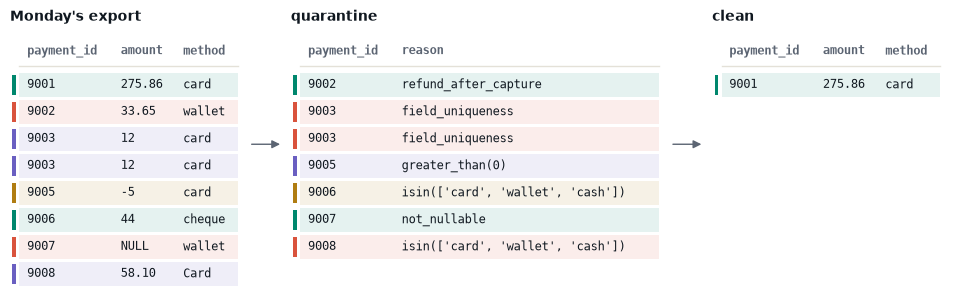

In [22]:
V.table_steps([
    {"title": "Monday's export", "df": PAYMENTS.select("payment_id", "amount", "method").to_pandas()},
    {"title": "quarantine", "df": quarantine.sort("index").select("payment_id", "reason").to_pandas()},
    {"title": "clean", "df": clean.select("payment_id", "amount", "method").to_pandas()},
], color_by="payment_id")